## Denosisng (by run or by group)

With "by_run" ASVs are computed within each run separately, with "by_group" ASVs are computed at the group level.

Group level potentially allows for greater sensitivity on rare ASVs, but if the samples are not highly standardized there is a risk on introducing biases due to the treating of a dishomogeneous error source as homogeneous.

In [1]:
%load_ext autoreload
%autoreload 2
import sys
sys.path.append("../")

import os
from os.path import join
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

In [2]:
from qiime2_utils import compile_manifest_files, update_runs_absolute_paths,full_preprocessing_pipeline

#### Make manifest files and data structure

In [3]:
base_path = "../DATA/"
preprocessing_type = ["by_group","by_run"][1]

# params
metadata_file_path  = join(base_path,"metadata/merged_metadata.parq")
raw_runs_folder     = join(base_path,"data/raw_reads/")
preprocessing_dir   = join(base_path,"data/preprocessing/denoising")
batch_size          = 5000
additional_groupby_fields = ["instrument_model"]

#%CAREFUL! may delete the whole preprocessing outcomes
full_preprocessing_path_cleaning = False

# run
manifest_file_paths = compile_manifest_files(raw_runs_folder=raw_runs_folder,
                                             preprocessing_dir=preprocessing_dir,
                                             metadata_file_path=metadata_file_path,
                                             additional_groupby_fields=additional_groupby_fields,
                                             batch_size=batch_size,
                                             full_preprocessing_path_cleaning=full_preprocessing_path_cleaning,
                                             preprocessing_type=preprocessing_type)


manifest_file_paths.to_csv(join(base_path,"metadata",f"{preprocessing_type}_manifest_file_paths.tsv"),sep="\t")

#### Preprocess

In [11]:
base_path = "../DATA/"
preprocessing_type = ["by_group","by_run"][1]

# import manifest file paths
manifest_file_paths = pd.read_csv(join(base_path,"metadata",f"{preprocessing_type}_manifest_file_paths.tsv"),sep="\t").pipe( lambda x : x.set_index(list(x.columns[:x.shape[1]-1])).iloc[:,-1])
update_runs_absolute_paths(manifest_file_paths) # ubdates raw_runs absolute paths in manifest files to match current system

# exec params
parallel = False
n_jobs   = 4

# computation params
cores       = 4
q_threshold = 30
clear_path  = True
from_step   = 1     # initial step of the preprocessing pipeline
to_step     = 2     # final step of the preprocessing pipeline (included)
overwrite   = False
skip_failed = False


# function compiled with assigned parameters
def compiled_function(manifest_file_path):
    import gc
    full_preprocessing_pipeline(manifest_file_path,
                                cores=cores,
                                q_threshold=q_threshold,
                                from_step=from_step,
                                to_step=to_step,
                                clear_path=clear_path,
                                overwrite=overwrite,
                                skip_failed=skip_failed)
    gc.collect()
    return None


# SEQUENTIAL [run over each group (defined by a manifest file)]
if not parallel:
    for manifest_file_path in manifest_file_paths:
        compiled_function(manifest_file_path)

# PARALLEL [run over each group (defined by a manifest file)]
elif parallel:
    from joblib import Parallel, delayed
    Parallel(n_jobs=n_jobs)(delayed(compiled_function)(mfp) for mfp in manifest_file_paths)



>>>> processing ./DATA/data/preprocessing/denoising/by_run/ERR1072955/manifest.tsv <<<
#samples = 1
Folder './DATA/data/preprocessing/denoising/by_run/ERR1072955' has been cleared.


-----------------------------------

0) import in qiime


-----------------------------------

1) remove primers
Running external command line application(s). This may print messages to stdout and/or stderr.
The command(s) being run are below. These commands cannot be manually re-run as they will depend on temporary files that no longer exist.

Command: cutadapt -u 0 --error-rate 0.1 --times 1 --overlap 3 --minimum-length 1 -q 0,0 --quality-base 33 --cores 4 -o /tmp/qiime2/marcello-pc/processes/24030-1794329291.01@marcello-pc/tmp/q2-OutPath-_zot0bow/ERR1072955_0_L001_R1_001.fastq.gz --adapter GGACTACHVGGGTWTCTAAT --front GTGCCAGCMGCCGCGGTAA /tmp/qiime2/marcello-pc/data/f8874611-d360-45dd-8062-b6f71c075c86/data/ERR1072955_0_L001_R1_001.fastq.gz

This is cutadapt 5.0 with Python 3.10.14
Command line parame

/home/marcello-pc/.local/share/mamba/envs/qiime2-amplicon-2025.4/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/marcello-pc/.local/share/mamba/envs/qiime2-amplicon-2025.4/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:182: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  context['result_data'] = pd.concat([context['result_data'], df])
/home/marcello-pc/.local/share/mamba/envs/qiime2-amplicon-2025.4/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:76: FutureWarning: Setting an item of incompatible dtype is



>>>> processing ./DATA/data/preprocessing/denoising/by_run/ERR1074806/manifest.tsv <<<
#samples = 1
Folder './DATA/data/preprocessing/denoising/by_run/ERR1074806' has been cleared.


-----------------------------------

0) import in qiime


-----------------------------------

1) remove primers
Running external command line application(s). This may print messages to stdout and/or stderr.
The command(s) being run are below. These commands cannot be manually re-run as they will depend on temporary files that no longer exist.

Command: cutadapt -u 0 --error-rate 0.1 --times 1 --overlap 3 --minimum-length 1 -q 0,0 --quality-base 33 --cores 4 -o /tmp/qiime2/marcello-pc/processes/24030-1794329291.01@marcello-pc/tmp/q2-OutPath-dlo7wg26/ERR1074806_0_L001_R1_001.fastq.gz --adapter GGACTACHVGGGTWTCTAAT --front GTGCCAGCMGCCGCGGTAA /tmp/qiime2/marcello-pc/data/afc463a6-41ea-4e4c-bc70-196ac13ce496/data/ERR1074806_0_L001_R1_001.fastq.gz

This is cutadapt 5.0 with Python 3.10.14
Command line parame

/home/marcello-pc/.local/share/mamba/envs/qiime2-amplicon-2025.4/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/marcello-pc/.local/share/mamba/envs/qiime2-amplicon-2025.4/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:182: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  context['result_data'] = pd.concat([context['result_data'], df])
/home/marcello-pc/.local/share/mamba/envs/qiime2-amplicon-2025.4/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:76: FutureWarning: Setting an item of incompatible dtype is



>>>> processing ./DATA/data/preprocessing/denoising/by_run/ERR1160451/manifest.tsv <<<
#samples = 1
Folder './DATA/data/preprocessing/denoising/by_run/ERR1160451' has been cleared.


-----------------------------------

0) import in qiime


-----------------------------------

1) remove primers
Running external command line application(s). This may print messages to stdout and/or stderr.
The command(s) being run are below. These commands cannot be manually re-run as they will depend on temporary files that no longer exist.

Command: cutadapt -u 0 --error-rate 0.1 --times 1 --overlap 3 --minimum-length 1 -q 0,0 --quality-base 33 --cores 4 -o /tmp/qiime2/marcello-pc/processes/24030-1794329291.01@marcello-pc/tmp/q2-OutPath-2otpndyo/ERR1160451_0_L001_R1_001.fastq.gz --adapter GGACTACNVGGGTWTCTAAT --front GTGYCAGCMGCCGCGGTAA /tmp/qiime2/marcello-pc/data/196af9b4-4de2-4935-9a17-669d3cf9e838/data/ERR1160451_0_L001_R1_001.fastq.gz

This is cutadapt 5.0 with Python 3.10.14
Command line parame

/home/marcello-pc/.local/share/mamba/envs/qiime2-amplicon-2025.4/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/marcello-pc/.local/share/mamba/envs/qiime2-amplicon-2025.4/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:182: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  context['result_data'] = pd.concat([context['result_data'], df])
/home/marcello-pc/.local/share/mamba/envs/qiime2-amplicon-2025.4/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:76: FutureWarning: Setting an item of incompatible dtype is

... (50 outputs left out)



>>>> processing ./DATA/data/preprocessing/denoising/by_run/ERR9735031/manifest.tsv <<<
#samples = 1
Folder './DATA/data/preprocessing/denoising/by_run/ERR9735031' has been cleared.


-----------------------------------

0) import in qiime


-----------------------------------

1) remove primers
Running external command line application(s). This may print messages to stdout and/or stderr.
The command(s) being run are below. These commands cannot be manually re-run as they will depend on temporary files that no longer exist.

Command: cutadapt -u 0 --error-rate 0.1 --times 1 --overlap 3 --minimum-length 1 -q 0,0 --quality-base 33 --cores 4 -o /tmp/qiime2/marcello-pc/processes/24030-1794329291.01@marcello-pc/tmp/q2-OutPath-vd_9t_fb/ERR9735031_0_L001_R1_001.fastq.gz --adapter GGACTACNVGGGTWTCTAAT --front GTGYCAGCMGCCGCGGTAA /tmp/qiime2/marcello-pc/data/f683311a-93c6-4915-9ca8-bafbf10a0d8e/data/ERR9735031_0_L001_R1_001.fastq.gz

This is cutadapt 5.0 with Python 3.10.14
Command line parame

/home/marcello-pc/.local/share/mamba/envs/qiime2-amplicon-2025.4/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/marcello-pc/.local/share/mamba/envs/qiime2-amplicon-2025.4/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:182: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  context['result_data'] = pd.concat([context['result_data'], df])
/home/marcello-pc/.local/share/mamba/envs/qiime2-amplicon-2025.4/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:76: FutureWarning: Setting an item of incompatible dtype is



>>>> processing ./DATA/data/preprocessing/denoising/by_run/ERR9735042/manifest.tsv <<<
#samples = 1
Folder './DATA/data/preprocessing/denoising/by_run/ERR9735042' has been cleared.


-----------------------------------

0) import in qiime


-----------------------------------

1) remove primers
Running external command line application(s). This may print messages to stdout and/or stderr.
The command(s) being run are below. These commands cannot be manually re-run as they will depend on temporary files that no longer exist.

Command: cutadapt -u 0 --error-rate 0.1 --times 1 --overlap 3 --minimum-length 1 -q 0,0 --quality-base 33 --cores 4 -o /tmp/qiime2/marcello-pc/processes/24030-1794329291.01@marcello-pc/tmp/q2-OutPath-w5zm2zfx/ERR9735042_0_L001_R1_001.fastq.gz --adapter GGACTACNVGGGTWTCTAAT --front GTGYCAGCMGCCGCGGTAA /tmp/qiime2/marcello-pc/data/134c20fb-d8c2-43d9-8c9b-c1bb3df4e8a3/data/ERR9735042_0_L001_R1_001.fastq.gz

This is cutadapt 5.0 with Python 3.10.14
Command line parame

/home/marcello-pc/.local/share/mamba/envs/qiime2-amplicon-2025.4/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):
/home/marcello-pc/.local/share/mamba/envs/qiime2-amplicon-2025.4/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:182: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  context['result_data'] = pd.concat([context['result_data'], df])
/home/marcello-pc/.local/share/mamba/envs/qiime2-amplicon-2025.4/lib/python3.10/site-packages/q2_demux/_summarize/_visualizer.py:76: FutureWarning: Setting an item of incompatible dtype is

## Compute ASVs at different sensitivities


In [5]:

%load_ext autoreload
%autoreload 2
import sys
sys.path.append("../")

import os
from os.path import join
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%matplotlib inline

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [83]:
## step 3 denoise and ASVs extraction

from qiime2_utils import denoise_ASVs_extraction2
import qiime2

cores = 3
n_jobs = 30

base_path = "../DATA/"
runsdir = join(base_path,"data/preprocessing/denoising/by_run")
Qiime_dir = [join(runsdir,run) for run in os.listdir(runsdir)]
    

# iterate over different omega_a values (default=1e-40)
#Omega_a = np.logspace(-10,-100,10)
Omega_a = np.logspace(-1,-100,20)
#Omega_a = [1e-10,1e-100]


# function run in parallel over multiple threads
def thred_function(qiime_dir):

    # import previous steps results
    print("\n3) denoise and ASVs extraction")
    seq = qiime2.Artifact.load(join(qiime_dir,'1_seq_noprimers.qza'))
    with open(join(qiime_dir,"2_truncation_length.txt"),mode="r") as f:
        truncation_length=int(f.readline().split("=")[-1]) # import truncation length computed in previous steps

    if truncation_length>100:
        # ASV outputs containers
        Asv_tab   = []
        Asv_seq   = []
        Asv_stats = []
        
        # compute ASV for different amega_a values
        for omega_a in Omega_a:
            print(f"{qiime_dir}\n----[{omega_a=}]")
        
            # run
            asv_tab_, asv_seq_, asv_stats_ = denoise_ASVs_extraction2(seq,truncation_length,cores=cores,create_patch=False,omega_a=omega_a)
            
            # prepare output
            asv_tab = asv_tab_.to_dataframe()
            asv_seq = pd.DataFrame({"seq":{str(seq.metadata['id']): str(seq) for seq in list(asv_seq_)}})
            asv_stats = asv_stats_.to_dataframe()
            asv_stats["omega_a"] = omega_a
            asv_stats = asv_stats.reset_index().set_index(["sample-id","omega_a"])
        
            # store
            Asv_tab  .append(asv_tab  )
            Asv_seq  .append(asv_seq  )
            Asv_stats.append(asv_stats)
        
        
        # collect results into pandas format
        Asv_tab = pd.concat(Asv_tab,axis=1,keys=Omega_a).fillna(0)
        Asv_tab.columns = Asv_tab.columns.set_names(names=["omega_a","sample"])
        Asv_tab.index.name = "ASV_id"
        
        Asv_seq = pd.concat(Asv_seq).drop_duplicates()
        Asv_seq.columns.name="ASV_id"
        
        Asv_stats = pd.concat(Asv_stats)
        
        # save on disk
        savepath = join(qiime_dir,"3_asv")
        os.makedirs(savepath,exist_ok=True)
        Asv_tab.T.sparse.to_dense().to_parquet(join(savepath,"asv_tab.parq"  ))
        Asv_seq                    .to_parquet(join(savepath,"asv_seq.parq"  )) 
        Asv_stats                  .to_parquet(join(savepath,"asv_stats.parq")) 


from qiime2_utils import create_patched_r_script, apply_omega_a_patch
PATCHED_R_SCRIPT_PATH = "./patched_dada2/run_dada_patched.R"

# --- before the parallel call ---
create_patched_r_script(PATCHED_R_SCRIPT_PATH)  # once, in the main process

# --- inside thred_function / denoise_ASVs_extraction2 ---
# remove the create_patched_r_script call, keep only:
apply_omega_a_patch(PATCHED_R_SCRIPT_PATH)


parallel = True
# SEQUENTIAL
if not parallel:
    for manifest_file_path in manifest_file_paths:
        compiled_function(manifest_file_path)

# PARALLEL
elif parallel:
    from joblib import Parallel, delayed
    Parallel(n_jobs=n_jobs)(delayed(thred_function)(qiime_dir) for qiime_dir in Qiime_dir)

Patched R script saved to: ./patched_dada2/run_dada_patched.R
OMEGA_A appears 13 times in patched script (expected 9)
Patch already applied, skipping.

3) denoise and ASVs extraction
../DATA/data/preprocessing/denoising/by_run/ERR1250604
----[omega_a=0.1]
Patch already applied, skipping.
Running external command line application(s). This may print messages to stdout and/or stderr.
The command(s) being run are below. These commands cannot be manually re-run as they will depend on temporary files that no longer exist.

Command: ./patched_dada2/run_dada_patched.R --input_directory /tmp/qiime2/ubuntu/data/11208322-8a0e-4bd7-b2f9-1bbec8f2c9be/data --output_path /tmp/tmpecznldqz/output.tsv.biom --output_track /tmp/tmpecznldqz/track.tsv --filtered_directory /tmp/tmpecznldqz --truncation_length 150 --trim_left 0 --max_expected_errors 2.0 --truncation_quality_score 2 --max_length Inf --pooling_method independent --chimera_method consensus --min_parental_fold 1.0 --allow_one_off False --num_thre

R version 4.3.3 (2024-02-29) 


Loading required package: Rcpp


DADA2: 1.30.0 / Rcpp: 1.0.14 / RcppParallel: 5.1.9 
2) Filtering .
3) Learning Error Rates
1818150 total bases in 12121 reads from 1 samples will be used for learning the error rates.
4) Denoise samples 
.
5) Remove chimeras (method = consensus)
6) Report read numbers through the pipeline
7) Write output
../DATA/data/preprocessing/denoising/by_run/ERR1250604
----[omega_a=6.158482110660267e-07]
Patch already applied, skipping.
Running external command line application(s). This may print messages to stdout and/or stderr.
The command(s) being run are below. These commands cannot be manually re-run as they will depend on temporary files that no longer exist.

Command: ./patched_dada2/run_dada_patched.R --input_directory /tmp/qiime2/ubuntu/data/11208322-8a0e-4bd7-b2f9-1bbec8f2c9be/data --output_path /tmp/tmpzfdnvh_4/output.tsv.biom --output_track /tmp/tmpzfdnvh_4/track.tsv --filtered_directory /tmp/tmpzfdnvh_4 --truncation_length 150 --trim_left 0 --max_expected_errors 2.0 --truncation_qual

Loading required package: Rcpp


DADA2: 1.30.0 / Rcpp: 1.0.14 / RcppParallel: 5.1.9 
2) Filtering .
3) Learning Error Rates
1818150 total bases in 12121 reads from 1 samples will be used for learning the error rates.
4) Denoise samples 
.
5) Remove chimeras (method = consensus)
6) Report read numbers through the pipeline
7) Write output

3) denoise and ASVs extraction
../DATA/data/preprocessing/denoising/by_run/ERR2579550
----[omega_a=0.1]
Patch applied: _denoise_single now accepts omega_a and uses patched R script
Running external command line application(s). This may print messages to stdout and/or stderr.
The command(s) being run are below. These commands cannot be manually re-run as they will depend on temporary files that no longer exist.

Command: ./patched_dada2/run_dada_patched.R --input_directory /tmp/qiime2/ubuntu/data/4b082d1c-b76a-4ff7-9f5a-1216e5e7dabb/data --output_path /tmp/tmp763eq_dv/output.tsv.biom --output_track /tmp/tmp763eq_dv/track.tsv --filtered_directory /tmp/tmp763eq_dv --truncation_length 151

... (848 outputs left out)

Loading required package: Rcpp


DADA2: 1.30.0 / Rcpp: 1.0.14 / RcppParallel: 5.1.9 
2) Filtering .
3) Learning Error Rates
8047200 total bases in 53648 reads from 1 samples will be used for learning the error rates.
4) Denoise samples 
.
5) Remove chimeras (method = consensus)
6) Report read numbers through the pipeline
7) Write output
../DATA/data/preprocessing/denoising/by_run/ERR9735042
----[omega_a=1e-100]
Patch already applied, skipping.
Running external command line application(s). This may print messages to stdout and/or stderr.
The command(s) being run are below. These commands cannot be manually re-run as they will depend on temporary files that no longer exist.

Command: ./patched_dada2/run_dada_patched.R --input_directory /tmp/qiime2/ubuntu/data/134c20fb-d8c2-43d9-8c9b-c1bb3df4e8a3/data --output_path /tmp/tmpdciprx2m/output.tsv.biom --output_track /tmp/tmpdciprx2m/track.tsv --filtered_directory /tmp/tmpdciprx2m --truncation_length 150 --trim_left 0 --max_expected_errors 2.0 --truncation_quality_score 2 --m

Loading required package: Rcpp


DADA2: 1.30.0 / Rcpp: 1.0.14 / RcppParallel: 5.1.9 
2) Filtering .
3) Learning Error Rates
8047200 total bases in 53648 reads from 1 samples will be used for learning the error rates.
4) Denoise samples 
.
5) Remove chimeras (method = consensus)
6) Report read numbers through the pipeline
7) Write output


In [90]:
x

Index([                   0.1,  6.158482110660267e-07,  3.792690190732254e-12,
       2.3357214690901212e-17,  1.438449888287666e-22,  8.858667904100868e-28,
       5.4555947811685145e-33,  3.359818286283788e-38, 2.0691380811147988e-43,
       1.2742749857031426e-48,  7.847599703514687e-54,  4.832930238571811e-59,
        2.976351441631313e-64, 1.8329807108324675e-69, 1.1288378916846929e-74,
        6.951927961775762e-80,  4.281332398719431e-85,  2.636650898730345e-90,
       1.6237767391887442e-95,                 1e-100],
      dtype='float64', name='omega_a')

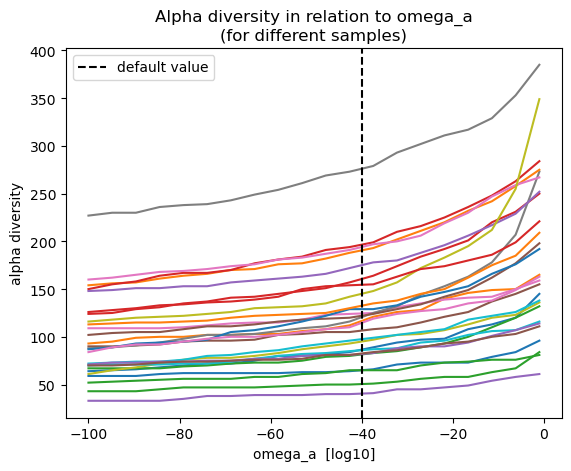

In [100]:
for qiime_dir in Qiime_dir:
    tab_filepath = join(qiime_dir,"3_asv","asv_tab.parq")
    if os.path.exists(tab_filepath):
        Asv_tab = pd.read_parquet(tab_filepath)
        f = (Asv_tab>0).sum(axis=1)
        y = f.values
        x = np.log10(f.index.get_level_values("omega_a"))
        plt.plot(x,y)#,label=qiime_dir.split("/")[-1])

plt.axvline(x=-40,linestyle="--",color="black",label="default value")
plt.title("Alpha diversity in relation to omega_a\n(for different samples)")
plt.xlabel("omega_a  [log10]")
plt.ylabel("alpha diversity")
plt.legend()

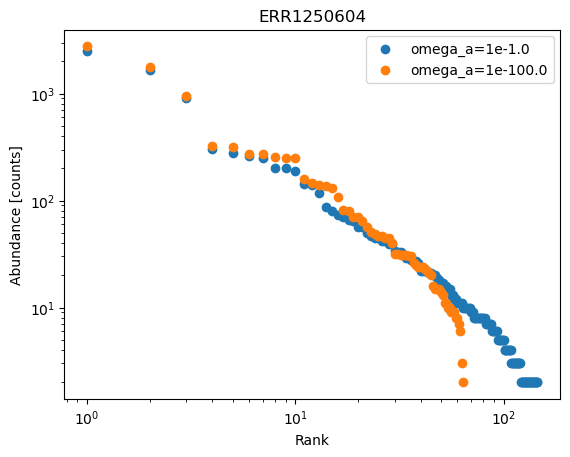

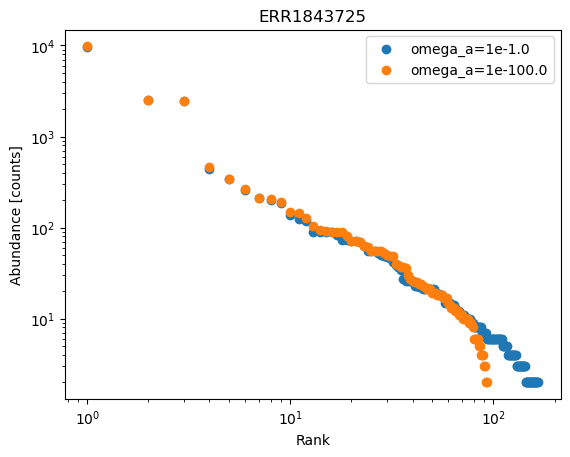

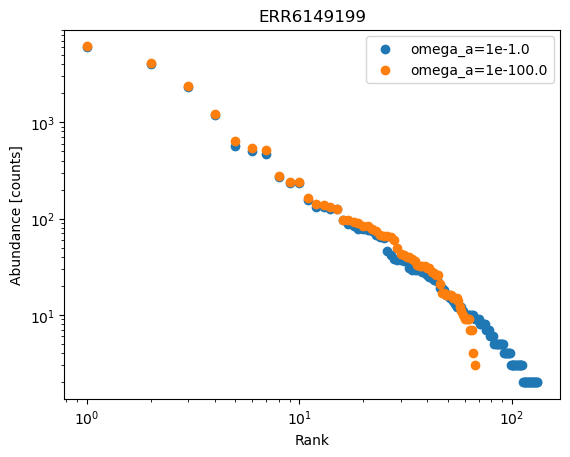

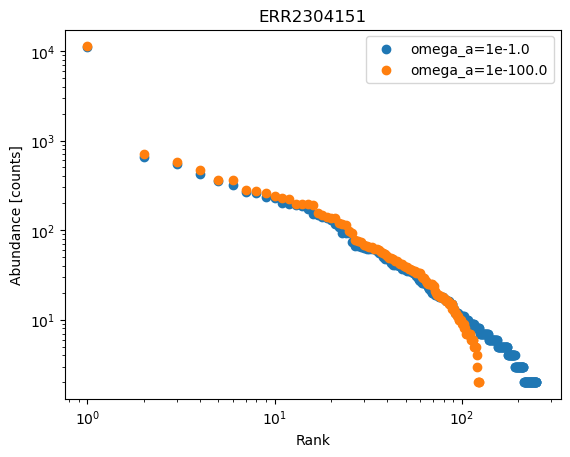

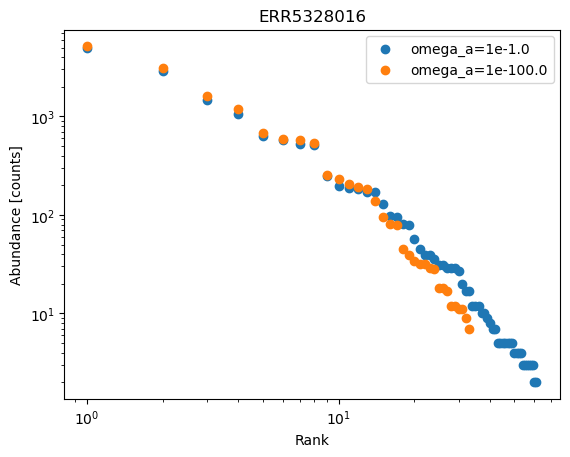

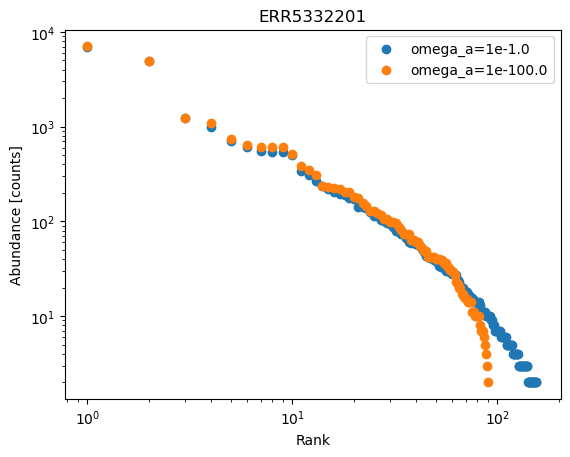

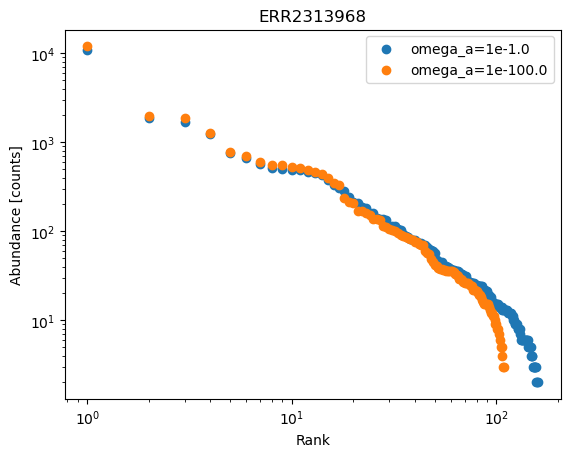

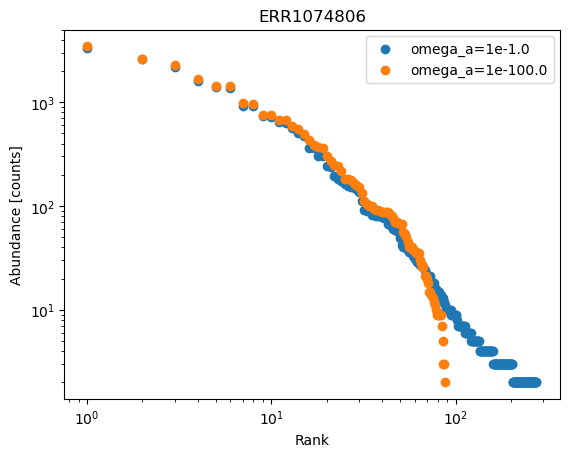

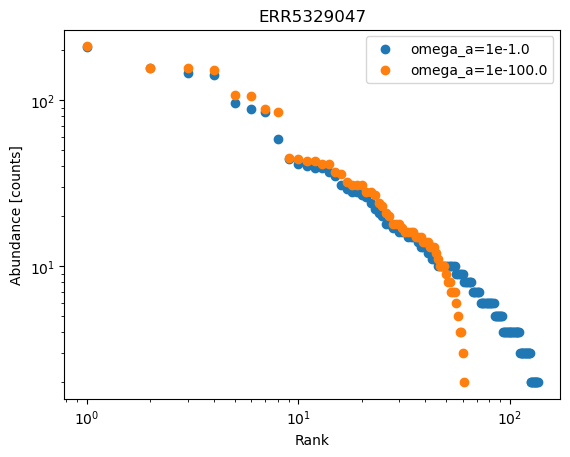

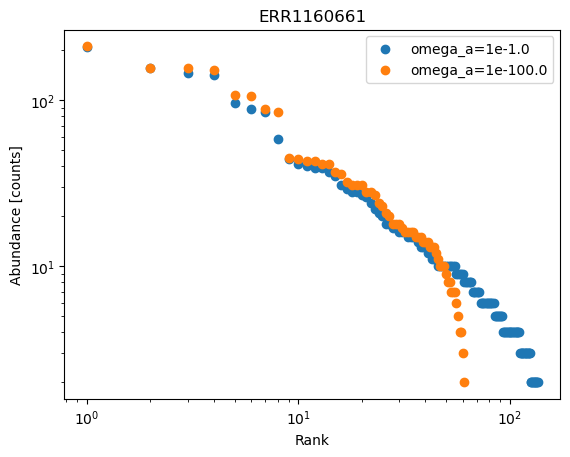

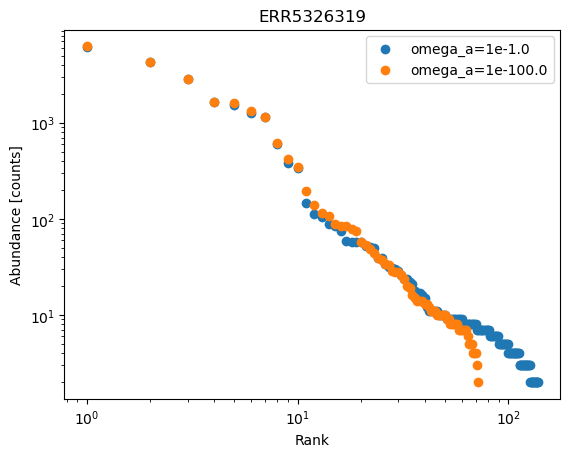

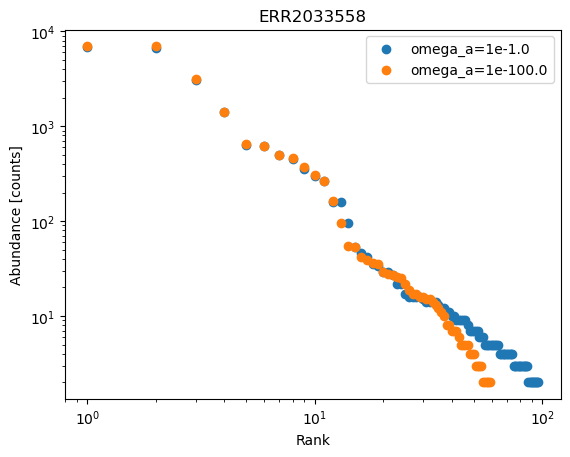

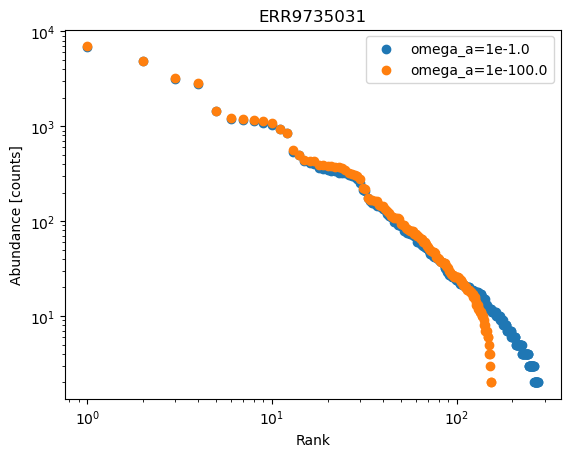

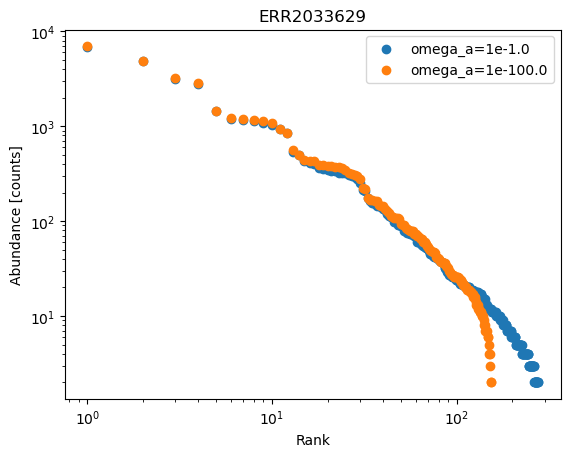

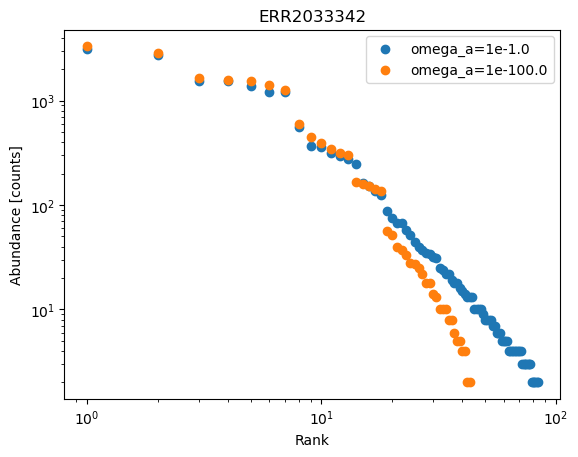

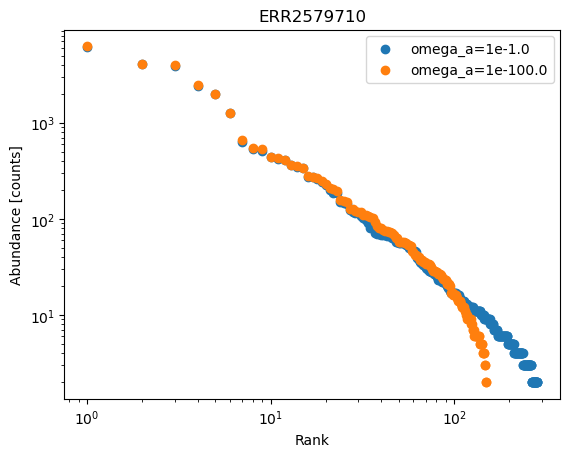

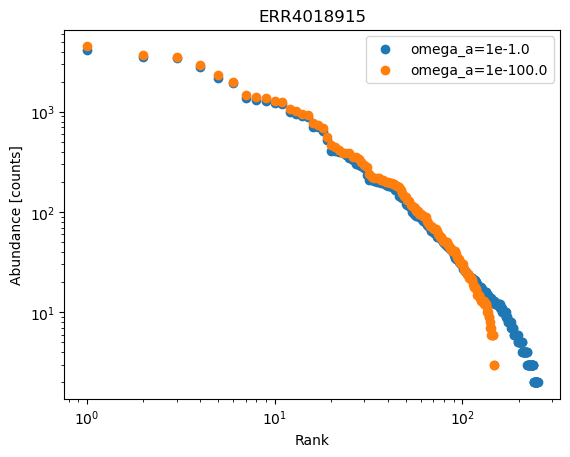

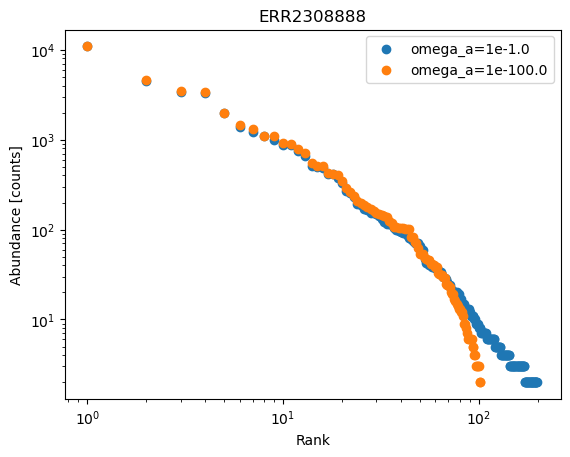

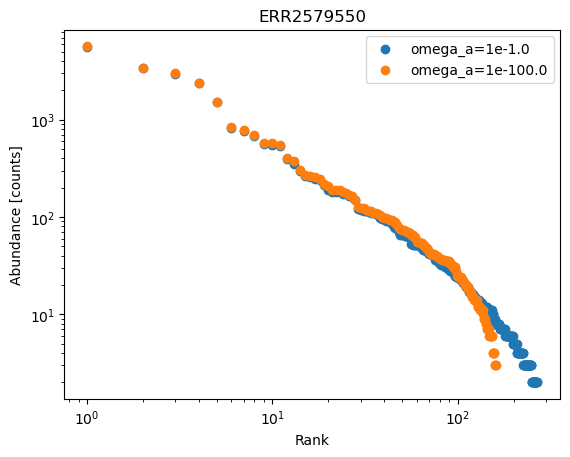

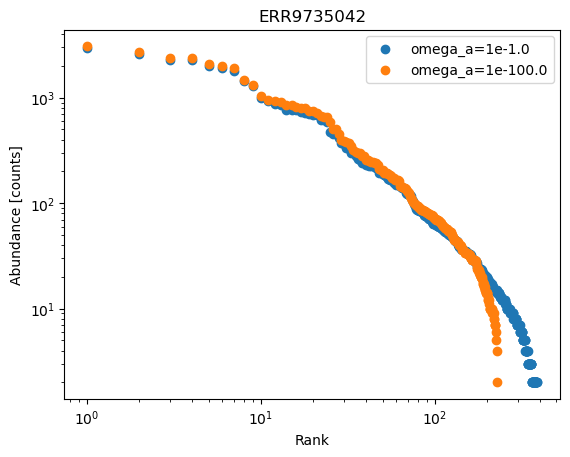

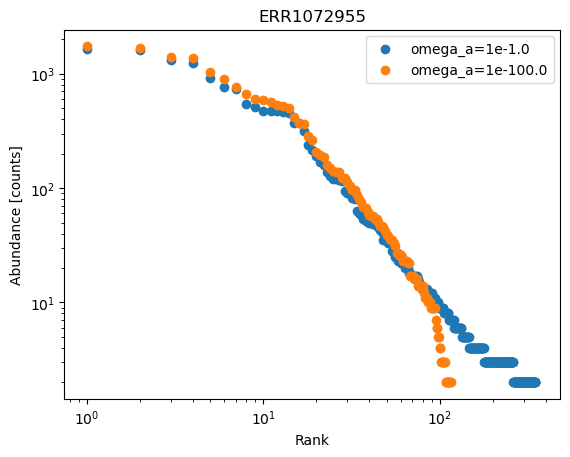

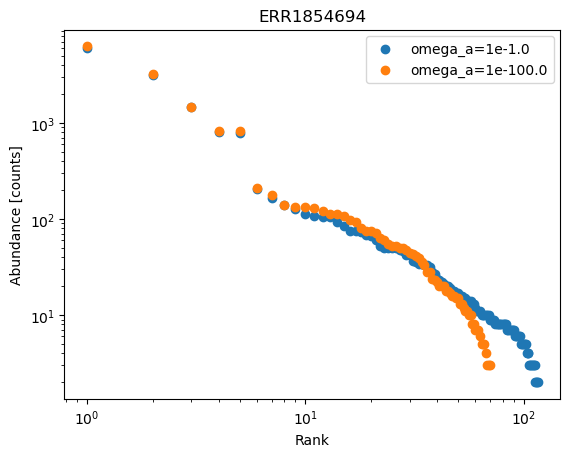

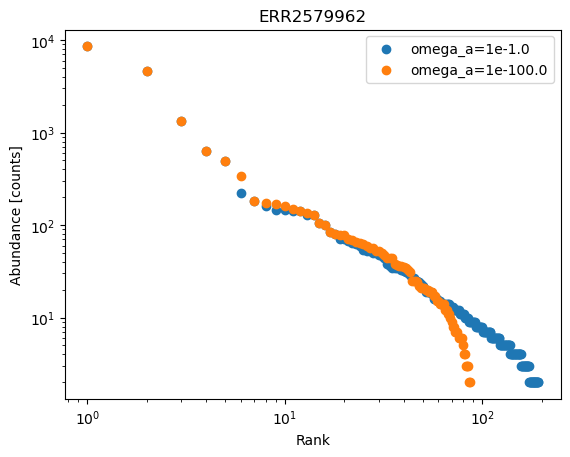

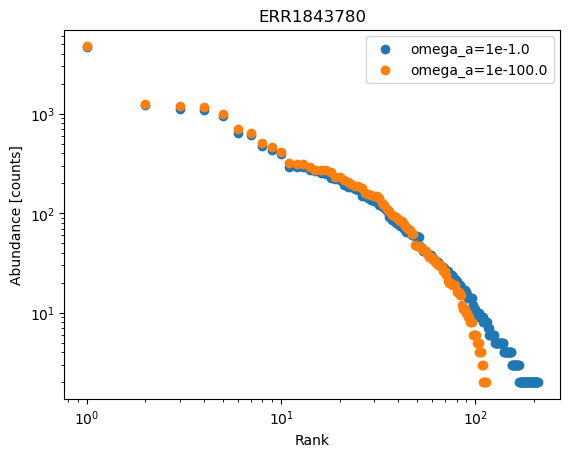

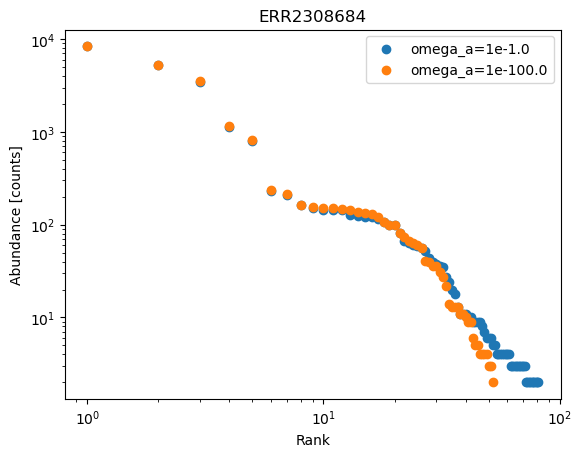

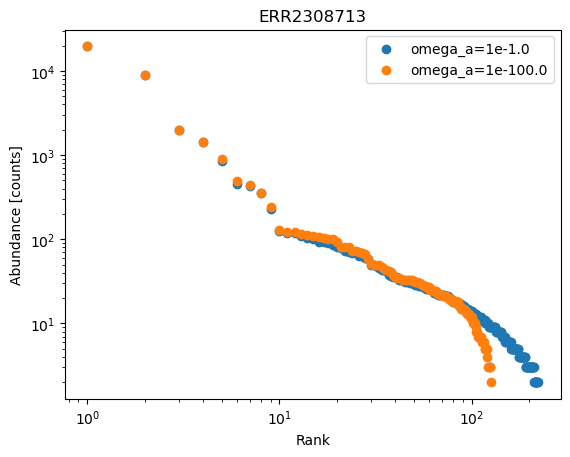

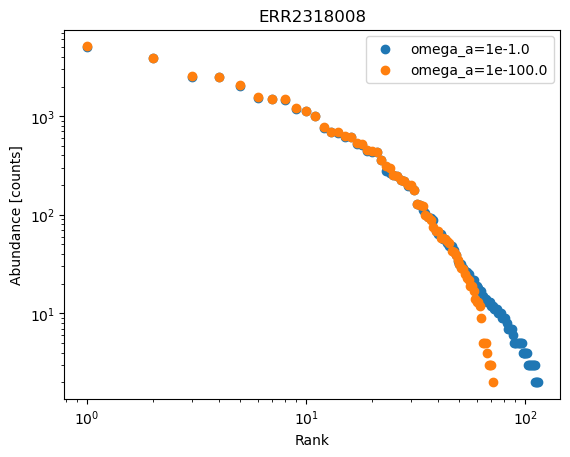

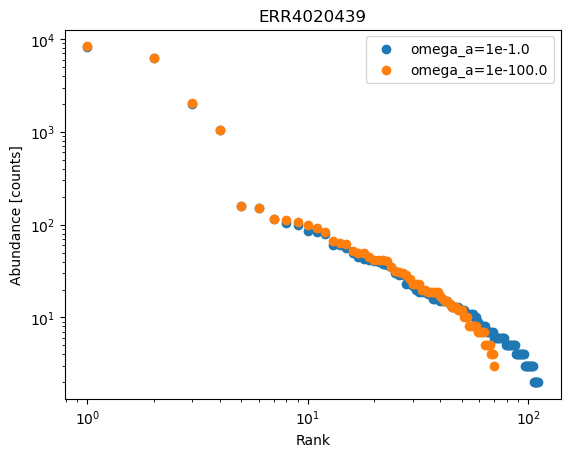

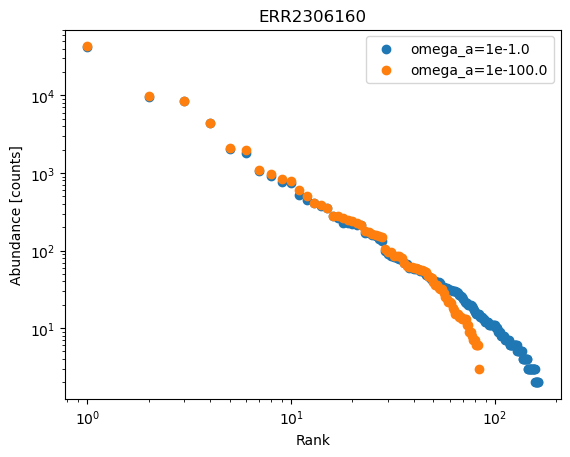

In [162]:
def compute_rank(x,axis=1):
    values = x.values
    ranks  = x.shape[axis]-np.argsort(np.argsort(x,axis=axis),axis=axis)
    return ranks, values

for qiime_dir in Qiime_dir:
    tab_filepath = join(qiime_dir,"3_asv","asv_tab.parq")
    if os.path.exists(tab_filepath):
        Asv_tab = pd.read_parquet(tab_filepath)


    x,y = compute_rank(Asv_tab)

    omega_a = np.log10(f.index.get_level_values("omega_a"))
    plt.scatter(x[0 ,:],y[0 ,:],label=f"omega_a=1e{omega_a[ 0]}")
    plt.scatter(x[-1,:],y[-1,:],label=f"omega_a=1e{omega_a[-1]}")

    plt.loglog()

    plt.title(qiime_dir.split("/")[-1])
    plt.ylabel("Abundance [counts]")
    plt.xlabel("Rank")
    plt.legend()
    plt.show()